# When do future masks dominate the initial action?

**Complete** · All intact and crossed mask replays saved · 113/113 replay jobs · ETA 0h 00m 00s

## Existing draws · all 18 checkpoints

The 180 saved draws keep data, initial-update masks and measurement masks fixed. Order agreement is the share of action pairs ordered the same way in two fresh draws, averaged by checkpoint. Pairs tied within 0.000001 are excluded. Winner agreement allows tied best actions.

| Arrivals | O3 order | Winner agreement | Loss order | RankMe order | Mask SD > |mean| | Median |mean| | Median mask SD | Median |mean| / SD |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 96 | 82.4% | 74.0% | 88.5% | 79.2% | 14/36 | 0.00317 | 0.00095 | 2.012 | 
 | 1000 | 52.4% | 37.9% | 54.9% | 53.0% | 33/36 | 0.00984 | 0.08641 | 0.276 | 

For each checkpoint and each alternative to ¼×, compare the absolute mean paired advantage with its SD across masks. Both use O3 units. The 36 contrasts are descriptive and share trajectories.

## Which metric and which draws drive the spread?

| Arrivals | Total variance | Loss variance | RankMe variance | 2 × covariance | Median RankMe share of component variance | Top 9 draw share | Largest checkpoint share | Order after trimming | Mask SD > |mean| after trimming |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 96 | 0.006556 | 0.000118 | 0.006379 | 0.000059 | 37.9% | 85.2% | 77.3% | 82.7% | 14/36 | 
 | 1000 | 0.096434 | 0.008537 | 0.091530 | -0.003633 | 93.9% | 47.3% | 29.3% | 54.0% | 32/36 | 

The O3 components use reconstruction MSE divided by its calibration SD and −0.25 × RankMe divided by its calibration SD. Variance is measured on the paired differences from ¼×. The tail diagnostic ranks checkpoint–draws by squared deviation from their checkpoint’s mean across both contrasts. The trim removes nine entire draws per horizon, then recomputes within-checkpoint statistics.

## Replay subset

The extension replays ten saved masks at seven checkpoints through +512 and uses their saved +1,000 results. The subset contains the highest apparent +1,000 opportunity and middle comparison per seed, plus the checkpoint contributing the most +96 variance. Three saved prefixes and suffixes are crossed at each checkpoint, switching after arrival 96. This subset deliberately includes high-variance states.

7 checkpoints have all ten intact replays.

| Arrivals | O3 order | Winner agreement | Loss order | RankMe order | Mask SD > |mean| | Median |mean| | Median mask SD | Median |mean| / SD |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 32 | 92.9% | 88.6% | 97.5% | 84.4% | 3/14 | 0.00805 | 0.00056 | 5.589 | 
 | 96 | 77.5% | 71.1% | 85.9% | 82.4% | 7/14 | 0.00363 | 0.00082 | 1.712 | 
 | 256 | 76.2% | 61.9% | 78.7% | 70.9% | 7/14 | 0.00315 | 0.00402 | 0.778 | 
 | 512 | 64.6% | 54.6% | 68.6% | 64.3% | 10/14 | 0.00799 | 0.07031 | 0.285 | 
 | 1000 | 55.2% | 43.5% | 57.6% | 53.0% | 12/14 | 0.01600 | 0.22701 | 0.268 | 

### Varying early versus late masks

| Arrivals | Complete checkpoints | SD varying first 96 | SD varying last 904 |
| --- | --- | --- | --- |
 | 32 | 7 | 0.02412 | 0.00000 | 
 | 96 | 7 | 0.14777 | 0.00000 | 
 | 256 | 7 | 0.19018 | 0.18080 | 
 | 512 | 7 | 0.33094 | 0.33987 | 
 | 1000 | 7 | 0.31558 | 0.28841 | 

Each entry takes the square root of the average within-row or within-column variance of paired O3 advantages, with the other segment fixed. Both summaries can include interactions.

### Determinism audit

The full repeated sequence matched all measured outcomes, final model and AdamW hashes, and actual masks. Continuation masks matched across actions. The audit verified one CUDA mask draw per stochastic call and unchanged CPU, NumPy and Python RNG state after ambient RNG perturbations and reversing the branch order.



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-mask-segments')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


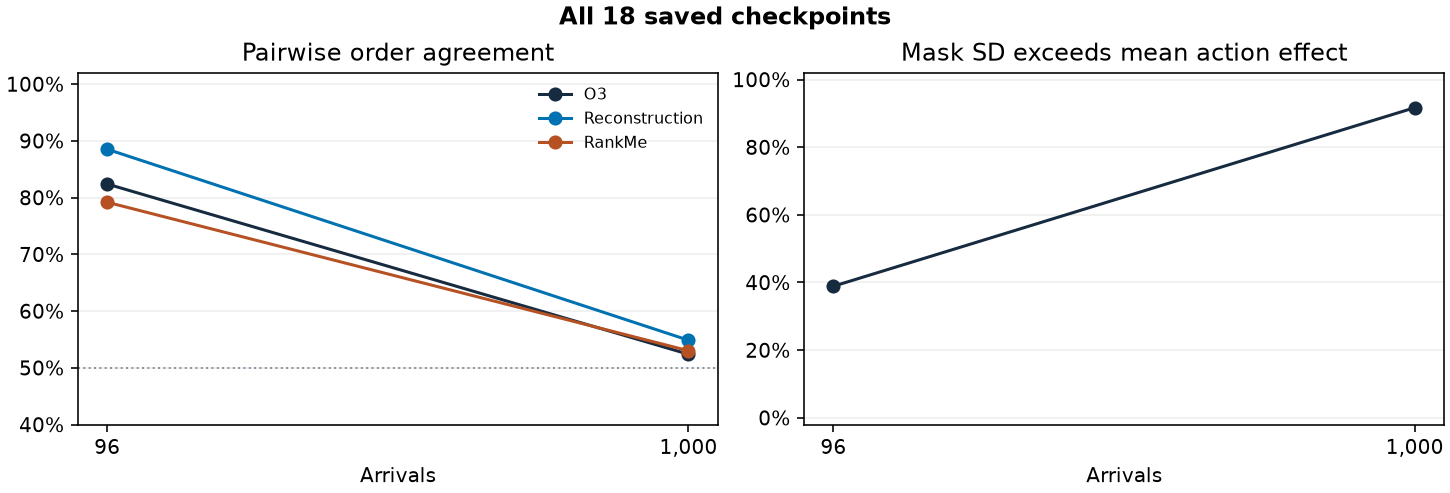

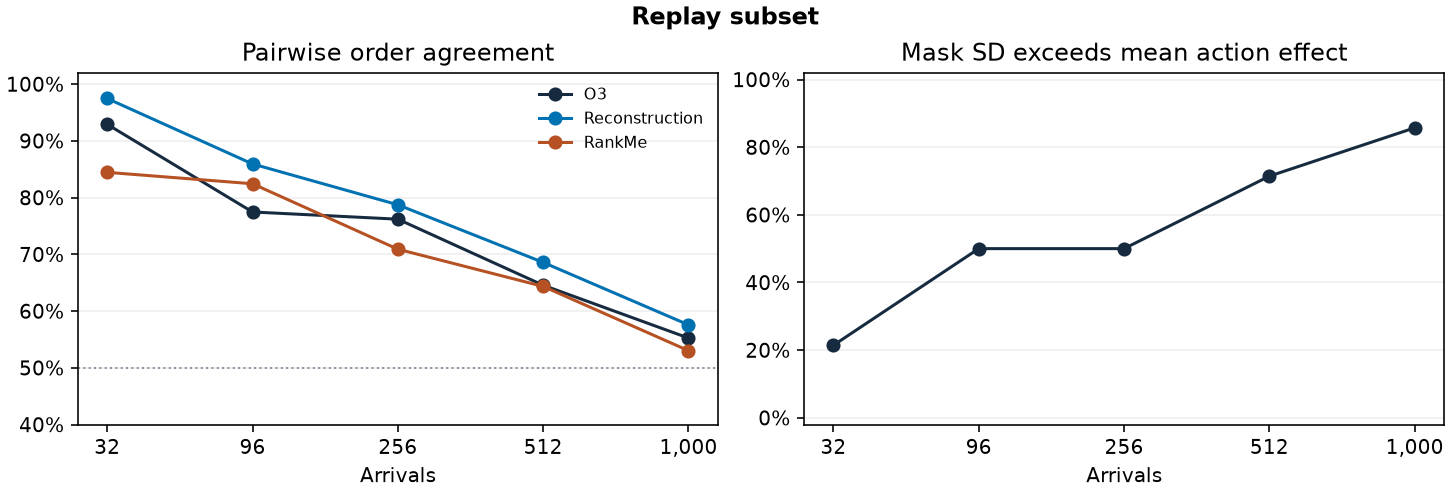